# Simulation of the Convolution of Neutron spectrum and Chopper opening function
Create increasingly difficult neutron spectra  
Create increasingly difficult chopper functions  
Convolute the functions  
Compare the outputs of the convoluted functions to the output of approximations

In [32]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import matplotlib.colors as mcolors
import math
import scipy as scp

from tof_helper_functions.tof_framework import RawTOFPointList, RebinnedTOFPointList, gauss3
from tof_helper_functions.tof_simulation_objects import Chopper, Detector
#plt.style.use('stylesheet.mplstyle')

In [47]:
# generate gaussian spectrum N(bin)
n = 4000
n_max =  n-1
a = 20000
mu =   900
sigma = 150

x_list = np.linspace(0,n_max,n)
gauss_signal_list = gauss3(x_list, a, mu, sigma)

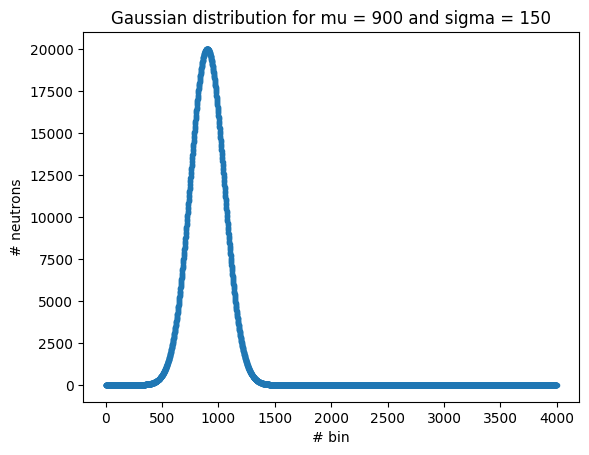

Text(0.5, 1.0, 'Incoming neutron spectrum')

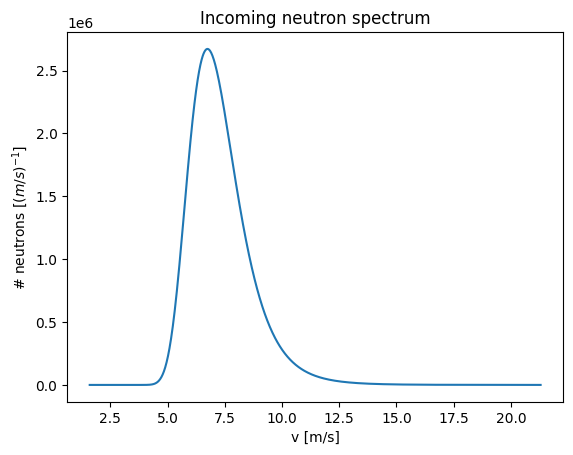

In [48]:
# feed the gaussian signal into the TOF framework
rawTOF_gaussian = RawTOFPointList(gauss_signal_list, 
                         s=631, 
                         label = "Gaussian")
v_max = 15.0
v_min = 4.5
v_step = 0.05
rebinnedTOF_gaussian = RebinnedTOFPointList(rawTOF_gaussian,
                                   v_min = v_min,
                                   v_max = v_max,
                                   v_step = v_step,
                                   label = "Rebinned Gaussian")


plt.plot(rawTOF_gaussian.bin_number, rawTOF_gaussian.N_bin, marker='.') 
plt.xlabel("# bin")
plt.ylabel("# neutrons")
plt.title(f"Gaussian distribution for mu = {mu} and sigma = {sigma}")
#plt.legend()
plt.show()

plt.clf()
plt.plot(rawTOF_gaussian.v[300:None], rawTOF_gaussian.N_v[300:None])
plt.xlabel("v [m/s]")
plt.ylabel(r"# neutrons [$(m/s)^{-1}$]")
plt.title("Incoming neutron spectrum")

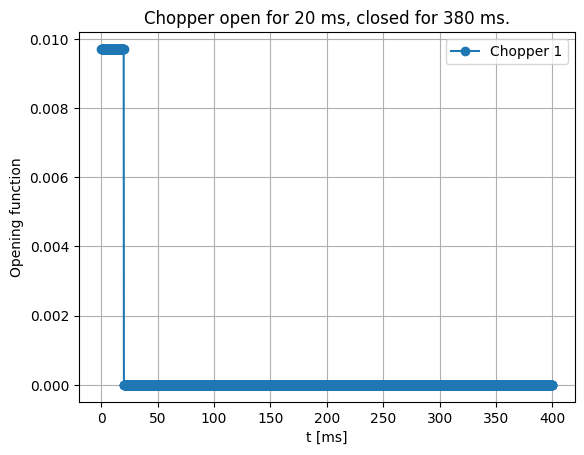

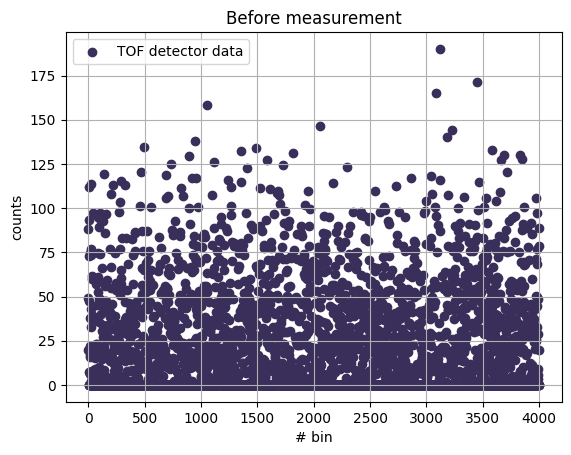

In [35]:
# chopper cycle open for 20 m and close for 380 ms
chopper_cycle_time_ms = 400
chopper_open_time_ms = 20
chopper1 = Chopper("Chopper 1", num_chop=2057, t_open_ms=chopper_open_time_ms, t_close_ms=chopper_cycle_time_ms-chopper_open_time_ms)
chopper1.renormalize_opening_function()
chopper1.plot()

# detector
detector1 = Detector(num_bins=4000, 
                     s_mm=639, 
                     do_cycle=False,
                     do_gaussian_noise=True,
                     sigma = 50)
detector1.plot(title="Before measurement")
detector1.measure(rawTOF_gaussian, chopper1)


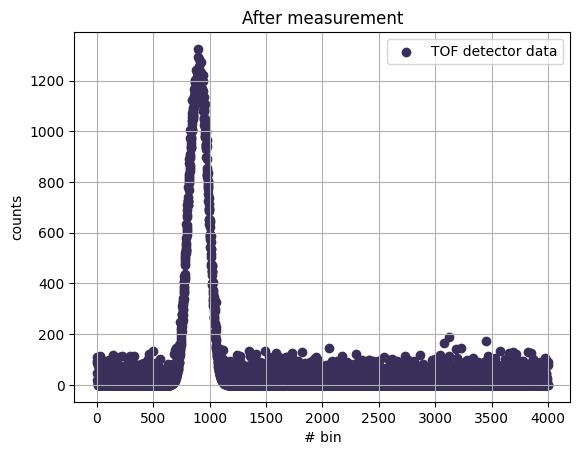

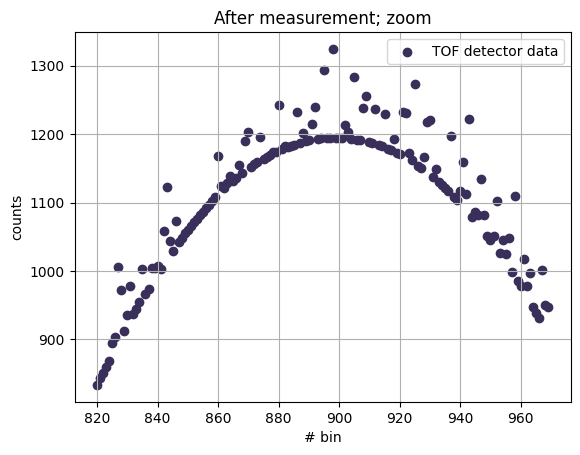

In [36]:
detector1.plot(title="After measurement", cut1=None, cut2=None)
detector1.plot(title="After measurement; zoom", cut1=820, cut2=970)

In [37]:
# analyze convoluted spectrum
t_convolution_offset = chopper_open_time_ms / 2.0
t_convolution_offset_err = (chopper1.t_open_ms - 0.0) * 0.6827 *0.5


rawTOF_gaussian_convoluted = RawTOFPointList(detector1.data, 
                         s=631, 
                         label = "Convoluted",
                         convolution_t=t_convolution_offset,
                         convolution_t_err=t_convolution_offset_err)

rebinnedTOF_gaussian_convoluted = RebinnedTOFPointList(rawTOF_gaussian_convoluted,
                                   v_min = v_min,
                                   v_max = v_max,
                                   v_step = v_step,
                                   label = "Rebinned convoluted")

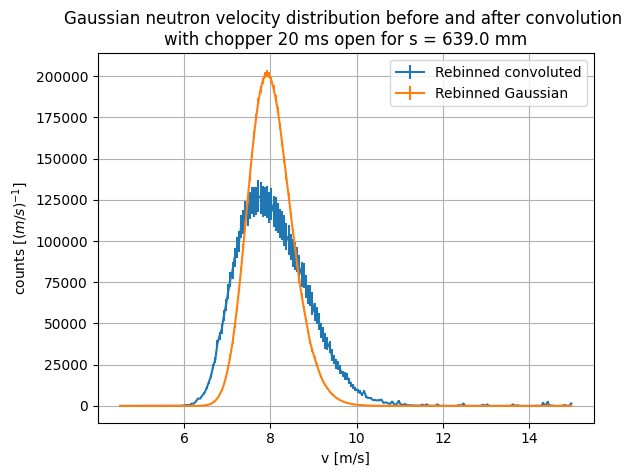

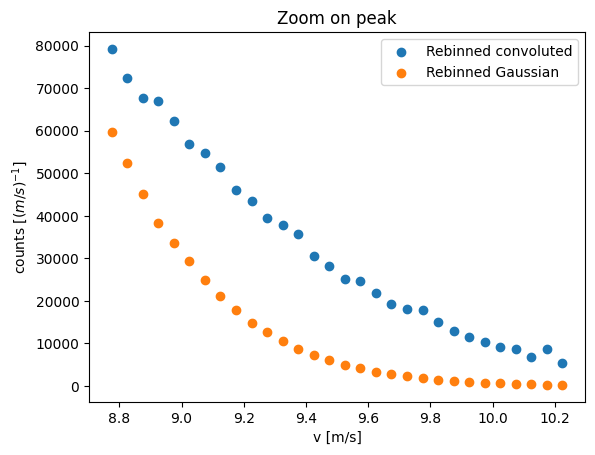

In [38]:

# plot spectra for debug
plt.errorbar(rebinnedTOF_gaussian_convoluted.v, 
             rebinnedTOF_gaussian_convoluted.N_v, 
             rebinnedTOF_gaussian_convoluted.N_v_err,
             label= rebinnedTOF_gaussian_convoluted.label)
plt.errorbar(rebinnedTOF_gaussian.v,
             rebinnedTOF_gaussian.N_v,
             rebinnedTOF_gaussian.N_v_err,
             label= rebinnedTOF_gaussian.label)
plt.xlabel("v [m/s]")
plt.ylabel(r"counts [$(m/s)^{-1}$]")
plt.legend()
plt.grid(True)
plt.title(f"Gaussian neutron velocity distribution before and after convolution \nwith chopper {chopper1.t_open_ms} ms open for s = {rebinnedTOF_gaussian.s} mm")
plt.show()

cut1 = 85
cut2 = 115
plt.scatter(rebinnedTOF_gaussian_convoluted.v[cut1:cut2], 
             rebinnedTOF_gaussian_convoluted.N_v[cut1:cut2], 
             label= rebinnedTOF_gaussian_convoluted.label)
plt.scatter(rebinnedTOF_gaussian.v[cut1:cut2],
             rebinnedTOF_gaussian.N_v[cut1:cut2],
             label= rebinnedTOF_gaussian.label)
plt.xlabel("v [m/s]")
plt.ylabel(r"counts [$(m/s)^{-1}$]")
plt.legend()
plt.title("Zoom on peak")
plt.show()

# NaN warner
for i in range(rebinnedTOF_gaussian.length):
    N_v = rebinnedTOF_gaussian[i].N_v
    if np.isnan(N_v):
        print(f"nan at index {i}")
        print(f"v = {rebinnedTOF_gaussian[i].v} m/s")
    elif np.isinf(N_v):
        print('+-inf')


Fit parameters: A=201111.79+-1515.40, mean=7.9723+-0.0043, sigma=0.49+-0.00
Fit parameters: A=127479.71+-1963.55, mean=7.9592+-0.0143, sigma=0.81+-0.01


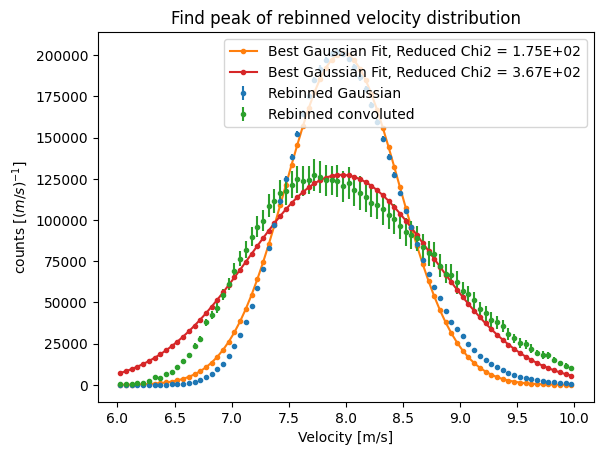

In [41]:
# analyze the pure spectrum and the spectrum after convolution by fitting a gauss to the peak
v_low, v_high = 6.0, 10.0
v_peak_gauss, v_peak_gauss_err = rebinnedTOF_gaussian.find_peak_velocity(gausstype='threepoints', 
                                                                         v_low=v_low, 
                                                                         v_high=v_high, 
                                                                         a0 = 200000.0, 
                                                                         mu0= 8.0, 
                                                                         sigma0=1.0, 
                                                                         do_plot=True, 
                                                                         do_print=True)
v_peak_convoluted, v_peak_convoluted_err = rebinnedTOF_gaussian_convoluted.find_peak_velocity(gausstype='threepoints', 
                                                                                          v_low=v_low, 
                                                                                          v_high=v_high, 
                                                                                          a0 = 250000.0, 
                                                                                          mu0= 8.0, 
                                                                                          sigma0=1.0, 
                                                                                          do_plot=True, 
                                                                                          do_print=True)

In [40]:
v_mean_gauss, v_mean_gauss_err = rebinnedTOF_gaussian.find_mean_velocity(do_print=True)
v_mean_convoluted1, v_mean_convoluted_err1 = rebinnedTOF_gaussian_convoluted.find_mean_velocity(do_print=True, do_newcode=False)
v_mean_convoluted2, v_mean_convoluted_err2 = rebinnedTOF_gaussian_convoluted.find_mean_velocity(do_print=True, do_newcode=True)

v_rms_gauss, v_rms_gauss_err = rebinnedTOF_gaussian.find_rms_velocity(do_print=True)
v_rms_convoluted, v_rms_convoluted_err = rebinnedTOF_gaussian_convoluted.find_rms_velocity(do_print=True)

Mean velocity for Rebinned Gaussian = 8.0198 +- 0.0010 m/s
Mean velocity for Rebinned convoluted = 8.0931 +- 0.1203 m/s
Mean velocity for Rebinned convoluted = 8.0931 +- 0.0067 m/s
Root mean squared velocity for Rebinned Gaussian = 8.0358 +- 0.0021 m/s
Root mean squared velocity for Rebinned convoluted = 8.1383 +- 0.0138 m/s
